# Reference solution: hidden drivers of defects

This notebook solves the task the way a careful analyst would, using only `data/`.
It follows the three EDA steps from the task definition:

1. **Describe** the data (DDA): structure, quality issues, cleaning, A1-A4.
2. **Identify salient features**: leakage, regime change, direct drivers, B1-B3.
3. **Interpret salient features**: the supplier question and the humidity optimum, C1-C2.

It produces `reference_answer.json` in the answer format of the task, then (section 4 only) checks it against the answer key.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

DATA = Path("../data")
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6})
pd.set_option("display.width", 140)

raw = pd.read_csv(DATA / "batches.csv")
suppliers = pd.read_csv(DATA / "suppliers.csv")
print(raw.shape)
raw.head()

(3060, 15)


,batch_id,production_date,line,shift,operator_id,supplier_code,machine_age_years,ambient_temp_c,mold_temp,humidity_pct,cycle_time_s,units_produced,defective_units,qc_inspection_min,rework_cost_eur
0,B-00001,2025-01-06,L1,NIGHT,OP-01,SP-01,3.7,15.8,214.8,39.9,30.1,586,23,19.0,105.77
1,B-00002,2025-01-06,L1,N,OP-04,SP-01,6.9,14.6,206.1,38.1,31.1,354,10,18.4,37.08
2,B-00003,2025-01-06,L1,Day,OP-06,SP-02,5.1,14.9,208.8,21.7,30.1,385,16,20.8,60.24
3,B-00004,2025-01-06,L1,night,OP-02,SP-01,6.0,15.1,207.5,64.8,28.1,532,32,24.0,127.65
4,B-00005,2025-01-06,L2,Day,OP-12,SP-01,5.6,18.2,205.7,60.4,28.0,813,30,20.9,129.64


## 1. Describe the data

### 1.1 Structure and summary statistics

In [2]:
raw.dtypes.to_frame('dtype').T

,batch_id,production_date,line,shift,operator_id,supplier_code,machine_age_years,ambient_temp_c,mold_temp,humidity_pct,cycle_time_s,units_produced,defective_units,qc_inspection_min,rework_cost_eur
dtype,str,str,str,str,str,str,float64,float64,float64,float64,float64,int64,int64,float64,float64


In [3]:
raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
machine_age_years,3060.0,7.19,4.69,1.00,4.20,5.40,7.40,21.5
ambient_temp_c,3060.0,21.91,4.62,10.40,17.60,23.10,25.80,30.6
mold_temp,3060.0,255.63,92.15,0.00,207.50,213.80,225.45,453.9
humidity_pct,3003.0,42.22,19.83,-1.00,27.30,42.60,59.10,75.0
cycle_time_s,3060.0,30.12,4.06,18.00,27.40,30.10,32.90,44.7
units_produced,3060.0,573.55,297.30,93.00,360.00,525.50,722.00,3387.0
defective_units,3060.0,32.10,26.40,2.00,16.00,25.00,40.00,457.0
qc_inspection_min,3060.0,22.52,2.90,14.30,20.60,22.20,24.10,58.4
rework_cost_eur,3060.0,135.64,112.06,7.85,65.54,105.68,169.38,1710.5


Two values stand out in `describe()` before any plotting:

- `humidity_pct` has a minimum of **-1**, which is impossible for relative humidity, so it is a sentinel for a missing reading.
- `mold_temp` has a minimum of **0** and a maximum above 400, both implausible for one unit of measurement.

### 1.2 Categorical columns

In [4]:
for col in ["line", "shift", "supplier_code"]:
    print(col, raw[col].map(repr).value_counts().to_dict(), "\n")

line {"'L1'": 870, "'L2'": 822, "'L3'": 748, "'L4'": 620} 

shift {"'Day'": 1486, "'Night'": 1022, "'DAY'": 93, "' Day'": 83, "'day'": 81, "'D'": 71, "'N'": 62, "'night'": 62, "'Night '": 51, "'NIGHT'": 49} 

supplier_code {"'SP-01'": 1241, "'SP-03'": 672, "'SP-02'": 647, "' Sp-01'": 85, "'sp-01'": 85, "'SP-01 '": 79, "'sp-03'": 51, "' Sp-02'": 45, "'SP-02 '": 41, "'SP-03 '": 40, "'sp-02'": 38, "' Sp-03'": 36} 



`shift` has spelling variants of two values (`Day`, `day`, `D`, `' Day'`, ...), and `supplier_code` has case and whitespace variants of the three codes in `suppliers.csv`. A join on the raw key would silently drop rows.

### 1.3 Duplicates

In [5]:
print("exact duplicate rows:", raw.duplicated().sum())
print("repeated batch_id:   ", raw["batch_id"].duplicated().sum())
dup_ids = raw.loc[raw["batch_id"].duplicated(), "batch_id"]
print("rows sharing a repeated id that are NOT exact copies:",
      (raw[raw["batch_id"].isin(dup_ids)].drop_duplicates()["batch_id"].duplicated()).sum())

exact duplicate rows: 60
repeated batch_id:    60
rows sharing a repeated id that are NOT exact copies: 0


Every repeated `batch_id` is an exact copy of another row (a double export), so dropping exact duplicates is safe and loses no information.

### 1.4 Mold temperature units

In [6]:
valid = raw[raw["mold_temp"] > 0]
print(valid.groupby("line")["mold_temp"].describe().round(1))
print("\nzeros per line:", raw[raw["mold_temp"] == 0].groupby("line").size().to_dict())

      count   mean   std    min    25%    50%    75%    max
line                                                       
L1    860.0  210.8   6.8  191.3  206.0  211.0  215.8  230.1
L2    807.0  211.0   7.0  189.3  206.3  211.0  216.1  232.2
L3    734.0  411.9  12.0  376.9  403.6  412.0  419.8  453.9
L4    609.0  210.8   6.9  184.8  206.2  210.9  215.5  232.3

zeros per line: {'L1': 10, 'L2': 15, 'L3': 14, 'L4': 11}


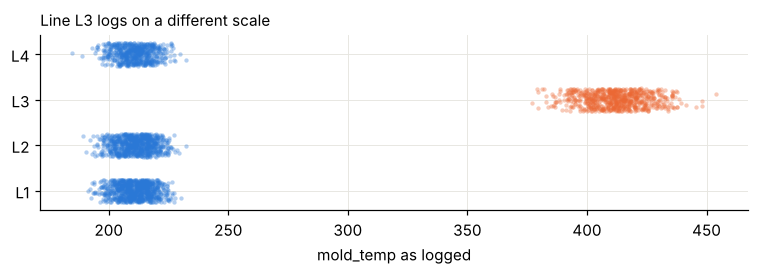

In [7]:
fig, ax = plt.subplots(figsize=(7, 2.6))
for i, (line, g) in enumerate(valid.groupby("line")):
    ax.scatter(g["mold_temp"], np.full(len(g), i) + np.random.default_rng(0).uniform(-0.25, 0.25, len(g)),
               s=8, color=ORANGE if line == "L3" else BLUE, alpha=0.35, linewidths=0)
ax.set_yticks(range(4), sorted(valid["line"].unique()))
ax.set_xlabel("mold_temp as logged")
ax.set_title("Line L3 logs on a different scale", loc="left", fontsize=10)
plt.tight_layout()

L3 sits around 410 while the other lines sit around 210. (410 - 32) × 5/9 ≈ 210, so **L3 logs in °F**. The zeros appear on every line and are sensor failures, not cold molds.

### 1.5 Cleaning

In [8]:
def clean(raw: pd.DataFrame, suppliers: pd.DataFrame) -> pd.DataFrame:
    df = raw.drop_duplicates().copy()
    df["shift"] = df["shift"].str.strip().str[0].str.upper().map({"D": "Day", "N": "Night"})
    df["supplier_code"] = df["supplier_code"].str.strip().str.upper()
    df = df.merge(suppliers, on="supplier_code", how="left", validate="many_to_one")
    df["humidity_pct"] = df["humidity_pct"].where(df["humidity_pct"] >= 0)   # -1 -> NaN
    df["mold_temp"] = df["mold_temp"].where(df["mold_temp"] > 0)             # 0 -> NaN
    is_f = df["line"] == "L3"
    df.loc[is_f, "mold_temp"] = (df.loc[is_f, "mold_temp"] - 32) * 5 / 9   # degF -> degC
    df["production_date"] = pd.to_datetime(df["production_date"])
    df["rate"] = df["defective_units"] / df["units_produced"]
    return df

df = clean(raw, suppliers)
assert df["shift"].notna().all() and df["supplier_name"].notna().all()
assert df.groupby("line")["mold_temp"].median().between(195, 225).all()
print(df.shape)
df[["shift", "supplier_name"]].value_counts().unstack()

(3000, 19)


supplier_name,Alpha,Beta,Gamma
shift,,,
Night,616,295,317
Day,852,460,460


### 1.6 Answers A1-A4

In [9]:
answers = {}
answers["A1_unique_batches"] = int(df["batch_id"].nunique())
answers["A2_missing_humidity_batches"] = int(df["humidity_pct"].isna().sum())
answers["A3_overall_defect_rate"] = round(float(df["defective_units"].sum() / df["units_produced"].sum()), 5)
answers["A4_median_mold_temp_c"] = round(float(df["mold_temp"].median()), 2)

print("mean of batch rates (not the overall rate):", round(df["rate"].mean(), 5))
print("missing humidity, NaN only (sentinels ignored):", raw.drop_duplicates()["humidity_pct"].isna().sum())
answers

mean of batch rates (not the overall rate): 0.05922
missing humidity, NaN only (sentinels ignored): 57


{'A1_unique_batches': 3000,
 'A2_missing_humidity_batches': 208,
 'A3_overall_defect_rate': 0.05601,
 'A4_median_mold_temp_c': 211.0}

The overall defect rate is the share of *all produced units* that were defective, so it is a pooled ratio. The mean of batch rates differs because the worst line also makes the smallest batches, which gives each of its few units too much weight.

## 2. Identify salient features

### 2.1 Leakage: columns determined by the outcome

In [10]:
num = df.select_dtypes("number").drop(columns=["rate"])
num.corrwith(df["defective_units"]).sort_values(ascending=False).round(3).to_frame("r with defective_units")

,r with defective_units
defective_units,1.000
rework_cost_eur,0.988
qc_inspection_min,0.730
units_produced,0.569
mold_temp,0.290
ambient_temp_c,0.194
humidity_pct,-0.018
machine_age_years,-0.158
cycle_time_s,-0.189


In [11]:
ratio = df["rework_cost_eur"] / df["defective_units"].replace(0, np.nan)
print("rework cost per defective part: median", round(ratio.median(), 2), "IQR", ratio.quantile([.25, .75]).round(2).tolist())
slope = np.polyfit(df["defective_units"], df["qc_inspection_min"], 1)
print(f"qc minutes = {slope[1]:.1f} + {slope[0]:.3f} x defective_units")

rework cost per defective part: median 4.21 IQR [3.95, 4.48]
qc minutes = 19.9 + 0.080 x defective_units


`rework_cost_eur` is almost exactly 4.2 € per defective part, and `qc_inspection_min` grows with the number of defects found. Both are **recorded after quality control and computed from the outcome**. They are excellent "predictors" only because they encode Y, so they must be excluded from any driver analysis (B2).

### 2.2 Univariate view: what a correlation matrix would suggest

In [12]:
cands = ["mold_temp", "humidity_pct", "cycle_time_s", "machine_age_years", "ambient_temp_c"]
df[cands].corrwith(df["rate"]).round(3).to_frame("Pearson r with defect rate")

,Pearson r with defect rate
mold_temp,0.352
humidity_pct,-0.043
cycle_time_s,-0.253
machine_age_years,0.337
ambient_temp_c,0.250


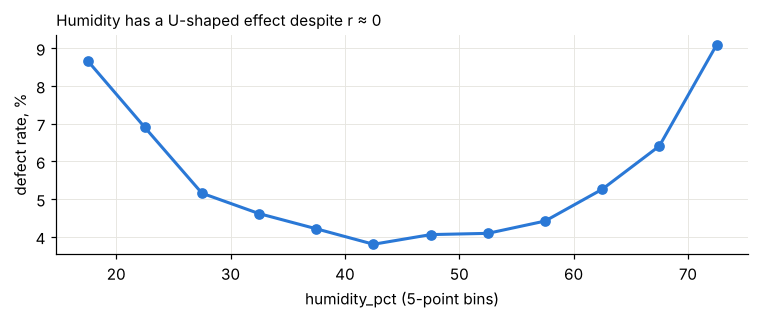

In [13]:
bins = pd.cut(df["humidity_pct"], np.arange(15, 76, 5))
by_hum = df.groupby(bins, observed=True).apply(lambda g: g["defective_units"].sum() / g["units_produced"].sum())
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot([b.mid for b in by_hum.index], by_hum.values * 100, color=BLUE, lw=2, marker="o", ms=6)
ax.set_xlabel("humidity_pct (5-point bins)"); ax.set_ylabel("defect rate, %")
ax.set_title("Humidity has a U-shaped effect despite r ≈ 0", loc="left", fontsize=10)
plt.tight_layout()

Pearson r for humidity is close to 0, yet the binned rate is clearly U-shaped. Linear correlation cannot see a symmetric non-linear effect. `machine_age_years` and `ambient_temp_c`, on the other hand, correlate with the rate. Section 2.4 tests whether those correlations are direct effects or confounding.

### 2.3 Regime change over time

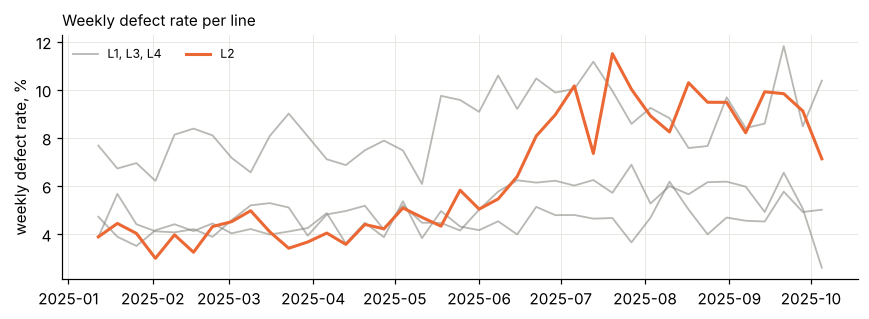

In [14]:
weekly = (df.set_index("production_date").groupby("line")[["defective_units", "units_produced"]]
          .resample("W").sum())
weekly = (weekly["defective_units"] / weekly["units_produced"]).unstack(0)
fig, ax = plt.subplots(figsize=(8, 3))
others = [l for l in weekly if l != "L2"]
for k, line in enumerate(others):
    ax.plot(weekly.index, weekly[line] * 100, lw=1.2, color=GRAY, alpha=0.6,
            label=", ".join(others) if k == 0 else None)
ax.plot(weekly.index, weekly["L2"] * 100, lw=2, color=ORANGE, label="L2")
ax.legend(ncol=2, frameon=False, fontsize=8); ax.set_ylabel("weekly defect rate, %")
ax.set_title("Weekly defect rate per line", loc="left", fontsize=10)
plt.tight_layout()

All lines drift up in summer (hotter hall, hotter molds), so a changepoint search on raw rates would be confounded by season. The search below therefore runs on **observed / expected** defects, where *expected* comes from a model of the process variables without any time term. For each line it finds the single split date that maximizes the Poisson log-likelihood ratio.

In [15]:
base_formula = ("rate ~ C(line) + C(supplier_name) + C(shift) + mold_temp + humidity_pct"
                "+ I(humidity_pct**2) + cycle_time_s")
model_df = df.dropna(subset=["mold_temp", "humidity_pct"]).copy()
base = smf.glm(base_formula, model_df, family=sm.families.Binomial(),
               var_weights=model_df["units_produced"]).fit(scale="X2")
model_df["expected"] = base.predict(model_df) * model_df["units_produced"]

def best_split(g: pd.DataFrame, margin_days: int = 14):
    daily = g.groupby("production_date")[["defective_units", "expected"]].sum().sort_index()
    o, e = daily["defective_units"].to_numpy(), daily["expected"].to_numpy()
    co, ce = o.cumsum(), e.cumsum()
    def seg(oo, ee): return oo * np.log(oo / ee)
    total = seg(co[-1], ce[-1])
    llr = [seg(co[i - 1], ce[i - 1]) + seg(co[-1] - co[i - 1], ce[-1] - ce[i - 1]) - total
           for i in range(margin_days, len(o) - margin_days)]
    i = int(np.argmax(llr)) + margin_days
    return daily.index[i].date(), float(max(llr)), co[i - 1] / ce[i - 1], (co[-1] - co[i - 1]) / (ce[-1] - ce[i - 1])

splits = pd.DataFrame([(l, *best_split(g)) for l, g in model_df.groupby("line")],
                      columns=["line", "split_date", "LLR", "O/E before", "O/E after"]).set_index("line")
splits.round(3)

,split_date,LLR,O/E before,O/E after
line,,,,
L1,2025-02-12,19.759,1.115,0.985
L2,2025-06-16,1238.384,0.750,1.333
L3,2025-05-02,5.313,1.028,0.983
L4,2025-03-28,4.187,1.043,0.985


Only L2 shows a large likelihood ratio: its observed/expected defect ratio jumps by a large factor at one date. The other lines' best splits are noise of much smaller magnitude.

In [16]:
regime_line = splits["LLR"].idxmax()
regime_date = splits.loc[regime_line, "split_date"]
df["regime"] = ((df["line"] == regime_line) & (df["production_date"] >= pd.Timestamp(regime_date))).astype(int)
answers["B3_regime_change"] = {"line": regime_line, "date": str(regime_date)}
answers["B3_regime_change"]

{'line': 'L2', 'date': '2025-06-16'}

### 2.4 Direct drivers: one multivariable model

Each batch is one observation of a noisy process. Besides binomial sampling noise, batches differ by an unobserved batch-level factor, so a large batch is *not* proportionally more informative than a small one. The model is therefore an OLS on the **empirical logit** of each batch, `log((d + 0.5) / (n - d + 0.5))`, with heteroskedasticity-robust (HC3) standard errors. It contains every candidate variable plus the controls (line, supplier, regime). A variable with a *direct* effect keeps a clear signal when everything else is held fixed, while a confounded one loses it.

In [17]:
model_df = df.dropna(subset=["mold_temp", "humidity_pct"]).copy()
model_df["y"] = np.log((model_df["defective_units"] + 0.5) / (model_df["units_produced"] - model_df["defective_units"] + 0.5))
full_formula = ("y ~ C(line) + C(supplier_name) + C(shift) + mold_temp + humidity_pct + I(humidity_pct**2)"
                "+ cycle_time_s + machine_age_years + ambient_temp_c + regime")
full = smf.ols(full_formula, model_df).fit(cov_type="HC3")
print(full.summary().tables[1])

                                coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------
Intercept                    -5.8909      0.224    -26.338      0.000      -6.329      -5.453
C(line)[T.L2]                 0.0643      0.020      3.251      0.001       0.026       0.103
C(line)[T.L3]                 0.1812      0.018     10.222      0.000       0.146       0.216
C(line)[T.L4]                 0.8971      0.050     17.997      0.000       0.799       0.995
C(supplier_name)[T.Beta]     -0.2528      0.021    -12.260      0.000      -0.293      -0.212
C(supplier_name)[T.Gamma]    -0.1230      0.016     -7.933      0.000      -0.153      -0.093
C(shift)[T.Night]             0.1729      0.013     13.438      0.000       0.148       0.198
mold_temp                     0.0281      0.001     26.380      0.000       0.026       0.030
humidity_pct                 -0.1057      0.002    -50.835  

In [18]:
op_model = smf.ols(full_formula.replace("C(line)", "C(operator_id)"), model_df).fit()
tests = {
    "mold_temp": full.pvalues["mold_temp"],
    "humidity_pct (linear + squared)": float(full.f_test("humidity_pct = 0, I(humidity_pct ** 2) = 0").pvalue),
    "cycle_time_s": full.pvalues["cycle_time_s"],
    "shift": full.pvalues["C(shift)[T.Night]"],
    "machine_age_years": full.pvalues["machine_age_years"],
    "ambient_temp_c": full.pvalues["ambient_temp_c"],
    # operator_id is nested in line: does replacing line dummies by operator dummies add anything?
    "operator_id (within line)": op_model.compare_f_test(smf.ols(full_formula, model_df).fit())[1],
}
pd.Series(tests, name="p-value").map(lambda p: f"{p:.2e}").to_frame()

,p-value
mold_temp,2.30e-153
humidity_pct (linear + squared),0.00e+00
cycle_time_s,4.48e-161
shift,3.64e-41
machine_age_years,8.72e-01
ambient_temp_c,2.68e-01
operator_id (within line),6.19e-02


Mold temperature, humidity, cycle time and shift are overwhelmingly significant (p < 0.001). Machine age, ambient temperature and operator add nothing once line and mold temperature are in the model:

- **Machine age** correlates with defects only because the oldest presses are on L4, the worst line.
- **Ambient temperature** acts *through* mold temperature (a hot hall heats the molds), so it has no effect of its own.
- **Operators** are tied to lines, and their apparent differences are line differences.

#### Side note: a tempting model that gets this wrong

A binomial GLM weighted by batch size looks like the textbook choice for defect counts. It assumes that a batch of 1,000 parts carries twice the information of a batch of 500. With batch-level variation that is false, the standard errors shrink too much, and null effects start to look significant:

In [19]:
glm_df = model_df.assign(rate=model_df["defective_units"] / model_df["units_produced"])
glm = lambda f: smf.glm(f.replace("y ~", "rate ~"), glm_df, family=sm.families.Binomial(),
                        var_weights=glm_df["units_produced"]).fit(scale="X2")
g_full, g_op = glm(full_formula), glm(full_formula.replace("C(line)", "C(operator_id)"))
from scipy import stats
F = (g_full.deviance - g_op.deviance) / (g_full.df_resid - g_op.df_resid) / g_op.scale
print("weighted quasi-binomial GLM, operator within line: p =",
      f"{stats.f.sf(F, g_full.df_resid - g_op.df_resid, g_op.df_resid):.1e}")
print("weighted quasi-binomial GLM, machine age:          p =", f"{g_full.pvalues['machine_age_years']:.1e}")

weighted quasi-binomial GLM, operator within line: p = 9.0e-04
weighted quasi-binomial GLM, machine age:          p = 4.4e-02


With this seed the weighted GLM declares the operator effect significant at p < 0.001, even though the operators have no effect by construction. Across 20 seeds the empirical-logit OLS recovered exactly the true driver set every time (`tests/test_reference.py`). This is a statistical trap that comes from the noise structure, which is realistic for production data.

In [20]:
name_map = {"mold_temp": "mold_temp", "humidity_pct (linear + squared)": "humidity_pct",
            "cycle_time_s": "cycle_time_s", "shift": "shift", "machine_age_years": "machine_age_years",
            "ambient_temp_c": "ambient_temp_c", "operator_id (within line)": "operator_id"}
answers["B1_direct_drivers"] = sorted(name_map[k] for k, p in tests.items() if p < 0.001)
answers["B2_leakage_columns"] = ["qc_inspection_min", "rework_cost_eur"]
answers["B1_direct_drivers"], answers["B2_leakage_columns"]

(['cycle_time_s', 'humidity_pct', 'mold_temp', 'shift'],
 ['qc_inspection_min', 'rework_cost_eur'])

## 3. Interpret salient features

### 3.1 Which supplier is best? (Simpson's paradox)

In [21]:
pooled = lambda g: g["defective_units"].sum() / g["units_produced"].sum()
overall = df.groupby("supplier_name").apply(pooled).rename("overall")
within = df.groupby(["line", "supplier_name"]).apply(pooled).unstack()
alloc = pd.crosstab(df["line"], df["supplier_name"], normalize="columns").round(2)
print("Defect rate overall:\n", (overall * 100).round(2).to_string(), "\n")
print("Defect rate within each line (%):\n", (within * 100).round(2), "\n")
print("Where each supplier's batches go (share of supplier's batches):\n", alloc)

Defect rate overall:
 supplier_name
Alpha    5.61
Beta     5.85
Gamma    5.41 

Defect rate within each line (%):
 supplier_name  Alpha  Beta  Gamma
line                             
L1              4.72  3.33   4.35
L2              6.31  5.30   6.39
L3              5.63  4.22   5.03
L4              9.73  8.28   8.89 

Where each supplier's batches go (share of supplier's batches):
 supplier_name  Alpha  Beta  Gamma
line                             
L1              0.36  0.12   0.30
L2              0.34  0.11   0.29
L3              0.26  0.15   0.31
L4              0.04  0.63   0.10


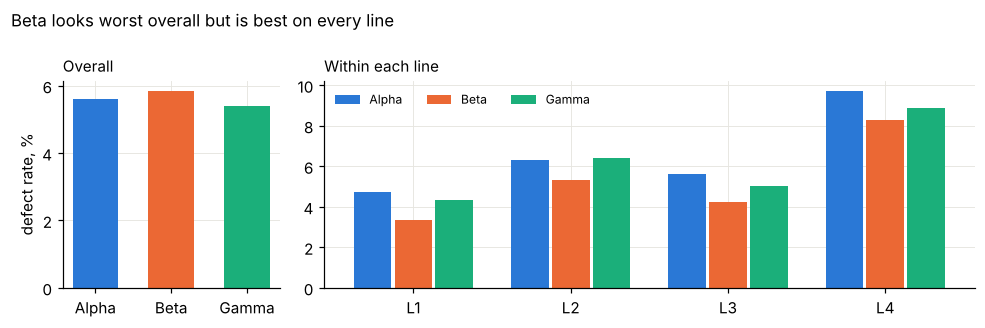

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3), gridspec_kw={"width_ratios": [1, 3]})
colors = {"Alpha": BLUE, "Beta": ORANGE, "Gamma": AQUA}
axes[0].bar(overall.index, overall * 100, color=[colors[s] for s in overall.index], width=0.6)
axes[0].set_title("Overall", loc="left", fontsize=10); axes[0].set_ylabel("defect rate, %")
w = 0.26
for k, s in enumerate(within.columns):
    axes[1].bar(np.arange(4) + (k - 1) * w, within[s] * 100, width=w - 0.02, color=colors[s], label=s)
axes[1].set_xticks(range(4), within.index); axes[1].legend(frameon=False, fontsize=8, ncol=3)
axes[1].set_title("Within each line", loc="left", fontsize=10)
fig.suptitle("Beta looks worst overall but is best on every line", x=0.01, ha="left", fontsize=11)
plt.tight_layout()

In [23]:
sup = full.params.filter(like="supplier_name")
print("Adjusted supplier effects vs Alpha (logit):\n", sup.round(3).to_string())
effects = pd.concat([pd.Series({"Alpha": 0.0}), sup.rename(lambda s: s.split("T.")[1].rstrip("]"))])
answers["C1_best_supplier"] = str(effects.idxmin())
answers["C1_best_supplier"]

Adjusted supplier effects vs Alpha (logit):
 C(supplier_name)[T.Beta]    -0.253
C(supplier_name)[T.Gamma]   -0.123


'Beta'

**Beta looks worst overall but is best within every line.** About 75 % of Beta's batches go to L4, the oldest line with the highest defect rate, while Alpha mostly supplies the better lines. The aggregate comparison mixes up "which supplier" with "which line". After adjusting for line and process conditions, Beta has the lowest defect rate, so switching away from it on the evidence of the overall average would be a costly mistake.

### 3.2 Humidity optimum

In [24]:
b1, b2 = full.params["humidity_pct"], full.params["I(humidity_pct ** 2)"]
h_star = -b1 / (2 * b2)

rng = np.random.default_rng(0)
boot = []
for _ in range(200):
    s = model_df.sample(len(model_df), replace=True, random_state=rng.integers(1 << 31))
    p = smf.ols(full_formula, s).fit().params
    boot.append(-p["humidity_pct"] / (2 * p["I(humidity_pct ** 2)"]))
lo, hi = np.percentile(boot, [2.5, 97.5])
answers["C2_optimal_humidity_pct"] = round(float(h_star), 1)
print(f"humidity optimum: {h_star:.1f} %  (bootstrap 95% CI {lo:.1f}-{hi:.1f})")

humidity optimum: 45.2 %  (bootstrap 95% CI 44.9-45.4)


The quadratic term is positive, so the curve has a minimum. The fitted optimum sits in the middle of the observed range (15-75 %), with a narrow bootstrap interval. Operationally, keeping the hall near this humidity, together with cooler molds and no rushed cycles, are the actionable levers.

## Answer

In [25]:
Path("reference_answer.json").write_text(json.dumps(answers, indent=2) + "\n")
print(json.dumps(answers, indent=2))

{
  "A1_unique_batches": 3000,
  "A2_missing_humidity_batches": 208,
  "A3_overall_defect_rate": 0.05601,
  "A4_median_mold_temp_c": 211.0,
  "B3_regime_change": {
    "line": "L2",
    "date": "2025-06-16"
  },
  "B1_direct_drivers": [
    "cycle_time_s",
    "humidity_pct",
    "mold_temp",
    "shift"
  ],
  "B2_leakage_columns": [
    "qc_inspection_min",
    "rework_cost_eur"
  ],
  "C1_best_supplier": "Beta",
  "C2_optimal_humidity_pct": 45.2
}


## 4. Check against the answer key

*This section uses `eval/ground_truth.json`, which no model ever sees. The scoring here is a provisional transcription of the metrics in `docs/task_design.md` (section 5); Stage 5 replaces it with `edabench.scorer`.*

In [26]:
gt = json.loads(Path("../eval/ground_truth.json").read_text())["questions"]
key = {"A1": "A1_unique_batches", "A2": "A2_missing_humidity_batches", "A3": "A3_overall_defect_rate",
       "A4": "A4_median_mold_temp_c", "B1": "B1_direct_drivers", "B2": "B2_leakage_columns",
       "B3": "B3_regime_change", "C1": "C1_best_supplier", "C2": "C2_optimal_humidity_pct"}
weights = {"A1": .075, "A2": .075, "A3": .075, "A4": .075, "B1": .15, "B2": .125, "B3": .125, "C1": .15, "C2": .15}

def f1(a, t):
    a, t = set(a), set(t)
    if not a and not t: return 1.0
    tp = len(a & t); return 2 * tp / (len(a) + len(t))

rows = []
for q, spec in gt.items():
    a, t = answers[key[q]], spec["truth"]
    if spec["type"] == "number":
        s = max(0.0, 1 - abs(a - t) / spec["scale"])
    elif spec["type"] == "set":
        s = f1(a, t)
    elif spec["type"] == "category":
        s = float(a == t)
    else:  # regime
        s = float(a["line"] == t["line"]) * max(0.0, 1 - abs((pd.Timestamp(a["date"]) - pd.Timestamp(t["date"])).days) / spec["scale_days"])
    rows.append((q, a, t, round(s, 3), weights[q]))
check = pd.DataFrame(rows, columns=["question", "reference", "truth", "score", "weight"]).set_index("question")
print("weighted total:", round((check["score"] * check["weight"]).sum(), 3))
check

weighted total: 0.998


,reference,truth,score,weight
question,,,,
A1,3000,3000,1.000,0.075
A2,208,208,1.000,0.075
A3,0.05601,0.056007,0.999,0.075
A4,211.0,211.0,1.000,0.075
B1,"[cycle_time_s, humidity_pct, mold_temp, shift]","[cycle_time_s, humidity_pct, mold_temp, shift]",1.000,0.150
B2,"[qc_inspection_min, rework_cost_eur]","[qc_inspection_min, rework_cost_eur]",1.000,0.125
B3,"{'line': 'L2', 'date': '2025-06-16'}","{'line': 'L2', 'date': '2025-06-16'}",1.000,0.125
C1,Beta,Beta,1.000,0.150
C2,45.2,45.0,0.987,0.150
